In [1]:
import json
import time
from itertools import combinations

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr, wilcoxon

SEED = 42

with open("../dados/metadados.json", encoding="utf-8") as f:
    meta = json.load(f)

colunas = meta["colunas_informativas"] + meta["colunas_ruido"]
treino = pd.read_csv("../dados/treino.csv")
teste = pd.read_csv("../dados/teste.csv")
X_train = treino[colunas]
X_test = teste[colunas]

indices = pd.read_csv("../resultados/amostra_indices.csv")["indice_teste"].values
X_amostra = X_test.loc[indices]
desvio = X_train.std().values

modelos = {
    "Random Forest": joblib.load("../resultados/modelos/random_forest.joblib"),
    "XGBoost": joblib.load("../resultados/modelos/xgboost.joblib"),
}
print("Amostra:", X_amostra.shape)

c:\Users\Gabriela Eliete\Desktop\tcc_xai_fiscal\env_tcc\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Amostra: (100, 10)


In [2]:
explicadores_shap = {nome: shap.TreeExplainer(m) for nome, m in modelos.items()}


def shap_pesos(nome, X):
    v = explicadores_shap[nome].shap_values(pd.DataFrame(X, columns=colunas))
    if isinstance(v, list):
        v = v[1]
    v = np.asarray(v)
    if v.ndim == 3:
        v = v[:, :, 1]
    return v


def lime_pesos(nome, X, seed, num_samples=5000):
    modelo = modelos[nome]
    explicador = LimeTabularExplainer(
        training_data=X_train.values,
        feature_names=colunas,
        class_names=["Classe 0", "Classe 1"],
        mode="classification",
        discretize_continuous=False,
        random_state=seed,
    )
    prever = lambda a: modelo.predict_proba(pd.DataFrame(a, columns=colunas))
    pesos = np.zeros((len(X), len(colunas)))
    for i, linha in enumerate(np.asarray(X)):
        exp = explicador.explain_instance(
            linha, prever, labels=(1,), num_features=len(colunas), num_samples=num_samples
        )
        for j, w in exp.as_map()[1]:
            pesos[i, j] = w
    return pesos


def metricas(orig, outra):
    """Compara duas explicações das mesmas instâncias. Retorna, por instância:
    correlação de Spearman entre rankings de importância, distância euclidiana entre
    importâncias normalizadas (somam 1) e se as 3 variáveis principais são as mesmas."""
    a, b = np.abs(orig), np.abs(outra)
    sp = np.array([spearmanr(x, y)[0] for x, y in zip(a, b)])
    dist = np.linalg.norm(a / a.sum(axis=1, keepdims=True) - b / b.sum(axis=1, keepdims=True), axis=1)
    t3a, t3b = np.argsort(-a, axis=1)[:, :3], np.argsort(-b, axis=1)[:, :3]
    igual = np.array([set(x) == set(y) for x, y in zip(t3a, t3b)], dtype=float)
    return sp, dist, igual


print("Funções definidas.")

Funções definidas.


In [3]:
# %% [CÉLULA 3] Experimento A: estabilidade frente a pequenas perturbações nos dados de entrada
# Ruído gaussiano com desvio de 1% e 5% do desvio-padrão de cada variável (5 réplicas).
# No LIME a semente é a mesma para original e perturbada, isolando o efeito da perturbação.
NIVEIS = [0.01, 0.05]
R = 5
rng = np.random.default_rng(SEED)
est = {}

for nome in modelos:
    t0 = time.time()
    orig = {"SHAP": shap_pesos(nome, X_amostra.values), "LIME": lime_pesos(nome, X_amostra, SEED)}
    for nivel in NIVEIS:
        acum = {m: ([], [], []) for m in orig}
        for _ in range(R):
            X_pert = X_amostra.values + rng.normal(0, 1, X_amostra.shape) * desvio * nivel
            pert = {"SHAP": shap_pesos(nome, X_pert), "LIME": lime_pesos(nome, X_pert, SEED)}
            for m in orig:
                for lista, valor in zip(acum[m], metricas(orig[m], pert[m])):
                    lista.append(valor)
        for m in orig:
            sp, dist, igual = (np.nanmean(np.array(l), axis=0) for l in acum[m])
            est[(nome, nivel, m)] = {"spearman": sp, "distancia": dist, "top3": igual}
    print(f"{nome}: concluído em {time.time() - t0:.0f}s")

linhas = []
for (nome, nivel, m), d in est.items():
    linhas.append(
        {
            "Modelo": nome,
            "Perturbação": f"{int(nivel * 100)}% do desvio",
            "Método": m,
            "Spearman médio": np.nanmean(d["spearman"]),
            "Distância euclidiana média": d["distancia"].mean(),
            "Top-3 preservado (%)": 100 * d["top3"].mean(),
        }
    )
tab_a = pd.DataFrame(linhas).set_index(["Modelo", "Perturbação", "Método"]).round(4)
print(tab_a)
tab_a.to_csv("../resultados/estabilidade_perturbacao.csv")

Random Forest: concluído em 202s
XGBoost: concluído em 29s
                                   Spearman médio  Distância euclidiana média  \
Modelo        Perturbação  Método                                               
Random Forest 1% do desvio SHAP            0.9855                      0.0118   
                           LIME            0.9995                      0.0007   
              5% do desvio SHAP            0.9572                      0.0360   
                           LIME            0.9975                      0.0034   
XGBoost       1% do desvio SHAP            0.9634                      0.0220   
                           LIME            0.9995                      0.0008   
              5% do desvio SHAP            0.8892                      0.0606   
                           LIME            0.9975                      0.0039   

                                   Top-3 preservado (%)  
Modelo        Perturbação  Método                        
Random Forest 

In [4]:
linhas = []
for nome in modelos:
    for nivel in NIVEIS:
        s, l = est[(nome, nivel, "SHAP")], est[(nome, nivel, "LIME")]
        ok = ~(np.isnan(s["spearman"]) | np.isnan(l["spearman"]))
        p_sp = wilcoxon(s["spearman"][ok], l["spearman"][ok], alternative="greater").pvalue
        p_dist = wilcoxon(s["distancia"], l["distancia"], alternative="less").pvalue
        linhas.append(
            {
                "Modelo": nome,
                "Perturbação": f"{int(nivel * 100)}% do desvio",
                "p (Spearman SHAP > LIME)": p_sp,
                "p (distância SHAP < LIME)": p_dist,
            }
        )
tab_h2 = pd.DataFrame(linhas).set_index(["Modelo", "Perturbação"])
print(tab_h2.map(lambda v: f"{v:.2e}"))
tab_h2.to_csv("../resultados/estabilidade_wilcoxon.csv")

                           p (Spearman SHAP > LIME) p (distância SHAP < LIME)
Modelo        Perturbação                                                    
Random Forest 1% do desvio                 1.00e+00                  1.00e+00
              5% do desvio                 1.00e+00                  1.00e+00
XGBoost       1% do desvio                 1.00e+00                  1.00e+00
              5% do desvio                 1.00e+00                  1.00e+00


In [5]:
SEMENTES = [1, 2, 3, 4, 5]
linhas = []
for nome in modelos:
    t0 = time.time()
    a1, a2 = shap_pesos(nome, X_amostra.values), shap_pesos(nome, X_amostra.values)
    execucoes = [lime_pesos(nome, X_amostra, s) for s in SEMENTES]
    sp_pares = np.nanmean(
        [metricas(x, y)[0] for x, y in combinations(execucoes, 2)], axis=0
    )
    top3_pares = np.mean([metricas(x, y)[2] for x, y in combinations(execucoes, 2)], axis=0)
    linhas.append(
        {
            "Modelo": nome,
            "SHAP: dif. máx. entre duas execuções": np.abs(a1 - a2).max(),
            "LIME: Spearman médio entre execuções": np.nanmean(sp_pares),
            "LIME: Top-3 preservado (%)": 100 * top3_pares.mean(),
        }
    )
    print(f"{nome}: concluído em {time.time() - t0:.0f}s")

tab_b = pd.DataFrame(linhas).set_index("Modelo")
print(tab_b.round(4).T)
tab_b.round(4).to_csv("../resultados/estabilidade_repeticao.csv")


Random Forest: concluído em 76s
XGBoost: concluído em 13s
Modelo                                Random Forest  XGBoost
SHAP: dif. máx. entre duas execuções         0.0000   0.0000
LIME: Spearman médio entre execuções         0.9424   0.9219
LIME: Top-3 preservado (%)                  88.1000  85.0000


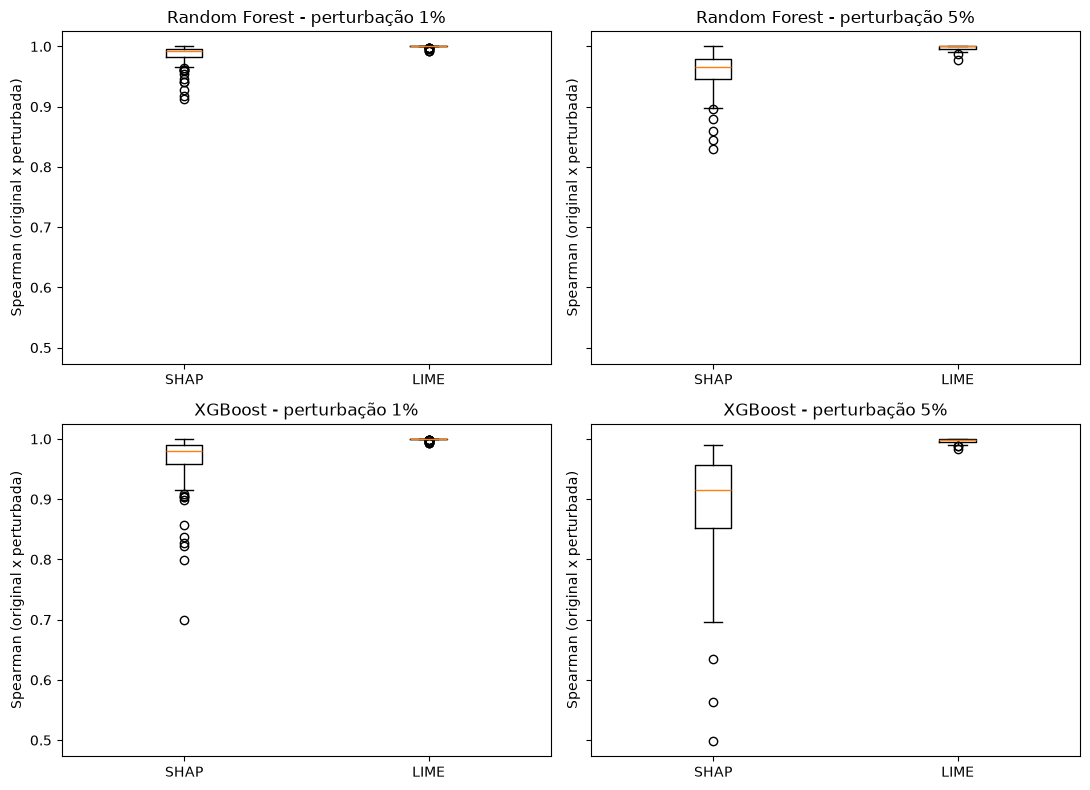

In [6]:
# %% [CÉLULA 6] Gráfico: distribuição da estabilidade por instância
fig, eixos = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for i, nome in enumerate(modelos):
    for j, nivel in enumerate(NIVEIS):
        ax = eixos[i, j]
        dados = [est[(nome, nivel, m)]["spearman"] for m in ["SHAP", "LIME"]]
        dados = [d[~np.isnan(d)] for d in dados]
        ax.boxplot(dados, tick_labels=["SHAP", "LIME"])
        ax.set_title(f"{nome} - perturbação {int(nivel * 100)}%")
        ax.set_ylabel("Spearman (original x perturbada)")
plt.tight_layout()
plt.savefig("../resultados/estabilidade_boxplot.png", dpi=300)
plt.show()


In [7]:
linhas = []
for nome in modelos:
    for nivel in NIVEIS:
        s, l = est[(nome, nivel, "SHAP")], est[(nome, nivel, "LIME")]
        ok = ~(np.isnan(s["spearman"]) | np.isnan(l["spearman"]))
        linhas.append(
            {
                "Modelo": nome,
                "Perturbação": f"{int(nivel * 100)}% do desvio",
                "Spearman SHAP": np.nanmean(s["spearman"]),
                "Spearman LIME": np.nanmean(l["spearman"]),
                "p (Spearman)": wilcoxon(s["spearman"][ok], l["spearman"][ok]).pvalue,
                "p (distância)": wilcoxon(s["distancia"], l["distancia"]).pvalue,
            }
        )
tab_bilateral = pd.DataFrame(linhas).set_index(["Modelo", "Perturbação"])
print(tab_bilateral.round(4))
tab_bilateral.to_csv("../resultados/estabilidade_wilcoxon_bilateral.csv")

                            Spearman SHAP  Spearman LIME  p (Spearman)  \
Modelo        Perturbação                                                
Random Forest 1% do desvio         0.9855         0.9995           0.0   
              5% do desvio         0.9572         0.9975           0.0   
XGBoost       1% do desvio         0.9634         0.9995           0.0   
              5% do desvio         0.8892         0.9975           0.0   

                            p (distância)  
Modelo        Perturbação                  
Random Forest 1% do desvio            0.0  
              5% do desvio            0.0  
XGBoost       1% do desvio            0.0  
              5% do desvio            0.0  
